# Deteksi Gambar Real vs AI-Generated: Swin Transformer vs ConvNeXt vs CLIP ViT-B/32

**Desain eksperimen**
- Dataset 2 kelas (`real`, `fake`), 60.000 citra; split bawaan: train 48.000 (24K/kelas) dan test 12.000 (6K/kelas).
- **Validation** diambil dari bagian test (hold-out stratified 10%, seed tetap) untuk early stopping dan memilih checkpoint terbaik.
- **Test (12.000 citra) hanya dipakai sekali di akhir**, setelah checkpoint terbaik dipilih berdasarkan validation.
- Resep training identik untuk ketiga model (optimizer, scheduler, epoch, augmentasi, seed). Yang berbeda hanya learning rate dan batch size per model (lihat `MODELS`).
- Kelas positif = `fake` (label 1).

## 1. Setup

In [ ]:
!pip install timm -q

In [ ]:
import os, json, time, copy, math, hashlib, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import timm

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix, roc_curve)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)
if device.type == "cuda":
    print("GPU    :", torch.cuda.get_device_name(0))
    print("VRAM   : %.1f GB" % (torch.cuda.get_device_properties(0).total_memory / 1e9))
print("torch", torch.__version__, "| timm", timm.__version__)

Device : cuda
GPU    : Tesla T4
VRAM   : 15.6 GB
torch 2.14.1+cu130 | timm 1.0.31


## 2. Konfigurasi

Semua pengaturan ada di satu sel ini. Sesuaikan `ZIP_PATH` dan `CLASS_NAMES` dengan nama folder dataset Anda.

In [ ]:
# ---------- Lokasi ----------
ZIP_PATH    = "/content/gdrive/MyDrive/Semester_5/Citra/archive.zip"
EXTRACT_DIR = "/content/AIvsReal"
OUT_DIR     = "/content/gdrive/MyDrive/Semester_5/Citra/AIvsReal_Results"     # hasil disimpan di Drive

# Struktur yang diharapkan:  <DATA_DIR>/train/<kelas>/*.jpg  dan  <DATA_DIR>/test/<kelas>/*.jpg
DATA_DIR    = EXTRACT_DIR            # diperbarui otomatis di sel 3 jika ada folder pembungkus
CLASS_NAMES = ["real", "fake"]       # <-- nama folder kelas; index 0 = real, index 1 = fake (positif)

# ---------- Eksperimen ----------
SEED         = 42
IMG_SIZE     = 224
EPOCHS       = 5
PATIENCE     = 2        # early stopping pada F1 validation
WARMUP_EPOCHS = 0.5
WEIGHT_DECAY = 0.05
HEAD_LR_MULT = 10       # head baru dilatih dengan lr x10
EFFECTIVE_BS = 32       # batch efektif sama untuk semua model (batch_size x accum_steps)
PRETRAINED   = True
NUM_WORKERS  = min(8, os.cpu_count() or 2)

# ---------- Model ----------
MODELS = {
    "CLIP-ViT-B32": dict(
        timm_name="vit_base_patch32_clip_224.openai",
        lr=2e-5, batch_size=32, accum_steps=1, grad_ckpt=False),
    "Swin-B": dict(
        timm_name="swin_base_patch4_window7_224.ms_in22k_ft_in1k",
        lr=5e-5, batch_size=32, accum_steps=1, grad_ckpt=False),
    "ConvNeXt-B": dict(
        timm_name="convnext_base.fb_in22k_ft_in1k",
        lr=5e-5, batch_size=32, accum_steps=1, grad_ckpt=False),
}
for k, v in MODELS.items():
    assert v["batch_size"] * v["accum_steps"] == EFFECTIVE_BS, f"{k}: batch efektif harus {EFFECTIVE_BS}"

os.makedirs(OUT_DIR, exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed()

## 3. Ekstrak dataset dan cek struktur

In [ ]:
import os
from google.colab import drive

# Jika mountpoint kotor atau masih tersisa dari sesi sebelumnya, force unmount terlebih dahulu
if os.path.exists('/content/gdrive'):
    !usr/bin/fusermount -u /content/gdrive 2>/dev/null || !umount -f /content/gdrive 2>/dev/null

try:
    drive.mount('/content/gdrive', force_remount=True)
except Exception as e:
    print("Gagal melakukan mounting secara standar, mencoba membersihkan paksa...")
    !rm -rf /content/gdrive
    drive.mount('/content/gdrive', force_remount=True)

Mounted at /content/gdrive


In [ ]:
import zipfile
with zipfile.ZipFile(ZIP_PATH, 'r') as z:
    z.extractall(EXTRACT_DIR)
print("Dataset diekstrak ke:", EXTRACT_DIR)

Dataset diekstrak ke: /content/AIvsReal


In [ ]:
# Cari folder yang berisi 'train' dan 'test' (menangani folder pembungkus ganda)
found = None
for root, dirs, files in os.walk(EXTRACT_DIR):
    if "train" in dirs and "test" in dirs:
        found = root; break
assert found is not None, "Folder 'train' dan 'test' tidak ditemukan di dalam dataset."
DATA_DIR = found
print("DATA_DIR =", DATA_DIR)

for split in ["train", "test"]:
    print(f"\n[{split}] subfolder:", sorted(os.listdir(os.path.join(DATA_DIR, split))))

DATA_DIR = /content/AIvsReal

[train] subfolder: ['fake', 'real']

[test] subfolder: ['fake', 'real']


In [ ]:
IMG_EXT = (".jpg", ".jpeg", ".png", ".webp", ".bmp")

def list_split(split):
    rows = []
    for label, cname in enumerate(CLASS_NAMES):
        cdir = os.path.join(DATA_DIR, split, cname)
        assert os.path.isdir(cdir), (f"Folder kelas tidak ada: {cdir}. "
                                     f"Isi {split}/: {os.listdir(os.path.join(DATA_DIR, split))}. "
                                     f"Perbaiki CLASS_NAMES di sel konfigurasi.")
        for f in sorted(os.listdir(cdir)):
            if f.lower().endswith(IMG_EXT):
                rows.append((os.path.join(cdir, f), label, cname))
    return pd.DataFrame(rows, columns=["filepath", "label", "class_name"])

df_train_full = list_split("train")
df_test       = list_split("test")

print("TRAIN:\n", df_train_full["class_name"].value_counts().to_string())
print("TEST :\n", df_test["class_name"].value_counts().to_string())

TRAIN:
 class_name
real    24000
fake    24000
TEST :
 class_name
real    6000
fake    6000


## 4. Cek duplikat memakai hash MD5 isi file


In [ ]:
def md5_file(p, chunk=1 << 20):
    h = hashlib.md5()
    with open(p, "rb") as f:
        while True:
            b = f.read(chunk)
            if not b: break
            h.update(b)
    return h.hexdigest()

df_train_full["md5"] = [md5_file(p) for p in tqdm(df_train_full["filepath"], desc="md5 train")]
df_test["md5"]       = [md5_file(p) for p in tqdm(df_test["filepath"],       desc="md5 test")]

dup_in_train = df_train_full["md5"].duplicated().sum()
dup_in_test  = df_test["md5"].duplicated().sum()
overlap      = set(df_train_full["md5"]) & set(df_test["md5"])
print("Duplikat di dalam train :", dup_in_train)
print("Duplikat di dalam test  :", dup_in_test)
print("File identik train<->test:", len(overlap))

md5 train:   0%|          | 0/48000 [00:00<?, ?it/s]

md5 test:   0%|          | 0/12000 [00:00<?, ?it/s]

Duplikat di dalam train : 25
Duplikat di dalam test  : 4
File identik train<->test: 12


In [ ]:
# Jika ada overlap train<->test, hapus dari TRAIN (test dibiarkan utuh sesuai split bawaan Anda).
if len(overlap) > 0:
    before = len(df_train_full)
    df_train_full = df_train_full[~df_train_full["md5"].isin(overlap)].reset_index(drop=True)
    print(f"Menghapus {before - len(df_train_full)} citra train yang identik dengan test.")
# Duplikat di dalam train sendiri dibuang agar tidak bocor ke validation
df_train_full = df_train_full.drop_duplicates("md5").reset_index(drop=True)
print("Ukuran train setelah pembersihan:", len(df_train_full))

 # buang duplikat di dalam test
df_test = df_test.drop_duplicates("md5").reset_index(drop=True)
print("Ukuran test setelah pembersihan :", len(df_test))

Menghapus 12 citra train yang identik dengan test.
Ukuran train setelah pembersihan: 47963
Ukuran test setelah pembersihan : 11996


### Pemindaian file rusak dan terpotong (scan + cache)

In [ ]:
from PIL import Image, ImageFile
from concurrent.futures import ProcessPoolExecutor
Image.MAX_IMAGE_PIXELS = None            # dataset sendiri; jangan anggap gambar besar sebagai rusak

CACHE_DIR = "/content/cache256"
os.makedirs(CACHE_DIR, exist_ok=True)
RESIZE = int(round(IMG_SIZE * 256 / 224))

# Sumber test asli (12.000) tanpa duplikat isi; dibuat dari disk, tidak bergantung pada df_test yang mungkin sudah terbagi
if "df_test_orig" not in globals():
    df_test_orig = list_split("test")
    df_test_orig["md5"] = [md5_file(p) for p in tqdm(df_test_orig["filepath"], desc="md5 test")]
df_test_orig = df_test_orig.drop_duplicates("md5").reset_index(drop=True)

def process_one(args):
    """Decode satu kali: deteksi file terpotong/rusak sekaligus simpan versi resize 256 (PNG, lossless)."""
    src, dst = args
    # if os.path.exists(dst): return "ok"
    try:
        ImageFile.LOAD_TRUNCATED_IMAGES = False
        status = "ok"
        try:
            img = Image.open(src); img.load()
        except Exception:
            ImageFile.LOAD_TRUNCATED_IMAGES = True       # terpotong? coba baca apa adanya
            img = Image.open(src); img.load()
            status = "terpotong"
        if img.mode in ("P", "LA") or "transparency" in img.info:
            img = img.convert("RGBA")
        img = T.Resize(RESIZE)(img.convert("RGB"))        # operasi yang sama dengan pipeline training
        tmp = dst + ".tmp"
        img.save(tmp, format="PNG", compress_level=1)
        os.replace(tmp, dst)                              # tulis atomik, tidak ada file setengah jadi
        return status
    except Exception as e:
        return f"rusak: {type(e).__name__}: {e}"

for d in (df_train_full, df_test_orig):
    d["cache_path"] = [os.path.join(CACHE_DIR, f"{m}.png") for m in d["md5"]]

jobs = pd.concat([d[["filepath", "cache_path"]] for d in (df_train_full, df_test_orig)]).drop_duplicates("cache_path")
jobs = list(zip(jobs["filepath"], jobs["cache_path"]))

with ProcessPoolExecutor(max_workers=os.cpu_count()) as ex:
    results = list(tqdm(ex.map(process_one, jobs, chunksize=16), total=len(jobs), desc="scan+cache"))
status = {dst: r for (src, dst), r in zip(jobs, results)}

# Gabungkan temuan lama: gambar yang sudah ada di cache dikembalikan "ok" oleh fungsi di atas
bad_path = os.path.join(OUT_DIR, "bad_images.csv")
if os.path.exists(bad_path):
    prev = pd.read_csv(bad_path)
    status.update({c: s for c, s in zip(prev["cache_path"], prev["status"]) if c in status})

kind = pd.Series(status).map(lambda s: s.split(":")[0])
print(kind.value_counts().to_string())

broken = {c for c, s in status.items() if s.startswith(("rusak", "terpotong"))}
df_train_full = df_train_full[~df_train_full["cache_path"].isin(broken)].reset_index(drop=True)
df_test_orig  = df_test_orig[~df_test_orig["cache_path"].isin(broken)].reset_index(drop=True)
print("Setelah membuang file rusak/terpotong -> train / test asli:", len(df_train_full), len(df_test_orig))

pd.DataFrame({"cache_path": list(status), "status": list(status.values())}) \
  .query("status != 'ok'").to_csv(bad_path, index=False)

md5 test:   0%|          | 0/12000 [00:00<?, ?it/s]

scan+cache:   0%|          | 0/59959 [00:00<?, ?it/s]

ok           59947
terpotong       12
Setelah membuang file rusak/terpotong -> train / test asli: 47954 11993


## 5. Buat train / validation dari split train

In [ ]:
print(len(df_test_orig))

11993


In [ ]:
# Train = split train asli (utuh). Val & Test = test asli dibagi dua, stratified.
df_train = df_train_full.reset_index(drop=True)
df_val, df_test = train_test_split(
    df_test_orig, test_size=0.5, stratify=df_test_orig["label"],
    random_state=SEED, shuffle=True)
df_val = df_val.reset_index(drop=True); df_test = df_test.reset_index(drop=True)

assert set(df_train.filepath).isdisjoint(df_val.filepath)
assert set(df_train.filepath).isdisjoint(df_test.filepath)
assert set(df_val.filepath).isdisjoint(df_test.fiulepath)

summary = pd.DataFrame({
    "split": ["train", "val", "test"],
    "total": [len(df_train), len(df_val), len(df_test)],
    "real":  [(d.label == 0).sum() for d in (df_train, df_val, df_test)],
    "fake":  [(d.label == 1).sum() for d in (df_train, df_val, df_test)]})
print(summary.to_string(index=False))

manifest = pd.concat([df_train.assign(split="train"), df_val.assign(split="val"),
                      df_test.assign(split="test")])
manifest.to_csv(os.path.join(OUT_DIR, "split_manifest.csv"), index=False)

split  total  real  fake
train  47954 23987 23967
  val   5996  2998  2998
 test   5997  2999  2998


In [ ]:
# ============================================================
# TOTAL DATASET AKHIR
# ============================================================

total_data = len(df_train) + len(df_val) + len(df_test)
total_real = (df_train.label == 0).sum() + (df_val.label == 0).sum() + (df_test.label == 0).sum()
total_fake = (df_train.label == 1).sum() + (df_val.label == 1).sum() + (df_test.label == 1).sum()

print("\n========== TOTAL DATASET AKHIR ==========")
print(f"Total seluruh data : {total_data:,}")
print(f"Total Real         : {total_real:,} ({total_real/total_data*100:.2f}%)")
print(f"Total Fake         : {total_fake:,} ({total_fake/total_data*100:.2f}%)")
print(f"Total Train        : {len(df_train):,}")
print(f"Total Validation   : {len(df_val):,}")
print(f"Total Test         : {len(df_test):,}")
print("=========================================")

assert total_data == total_real + total_fake
assert total_data == len(df_train) + len(df_val) + len(df_test)


========== TOTAL DATASET AKHIR ==========
Total seluruh data : 59,947
Total Real         : 29,984 (50.02%)
Total Fake         : 29,963 (49.98%)
Total Train        : 47,954
Total Validation   : 5,996
Total Test         : 5,997


In [ ]:
# 1) manifest lengkap dengan kolom cache_path (urutan baris penting untuk test)
m = pd.concat([df_train.assign(split="train"), df_val.assign(split="val"), df_test.assign(split="test")])
m.to_csv(os.path.join(OUT_DIR, "split_manifest_cache.csv"), index=False)

# 2) cache gambar sebagai satu file tar (tanpa kompresi; PNG sudah terkompresi)
# !tar -cf "$OUT_DIR/cache256.tar" -C /content cache256
# !ls -lh "$OUT_DIR/cache256.tar"

-rw------- 1 root root 7.7G Nov  3 13:23 /content/gdrive/MyDrive/Semester_5/Citra/AIvsReal_Results/cache256.tar


In [ ]:
import os

# Periksa lokasi cache
CACHE_DIR = "/content/cache256"

print("=== PEMERIKSAAN CACHE ===")

if os.path.exists(CACHE_DIR):
    print("Cache ditemukan:", CACHE_DIR)

    files = []
    for root, dirs, filenames in os.walk(CACHE_DIR):
        files.extend(
            os.path.join(root, f)
            for f in filenames
        )

    print("Jumlah file:", len(files))
    print("Ukuran folder:",
          round(sum(os.path.getsize(f) for f in files) / (1024**3), 2),
          "GB")
else:
    print("Cache tidak ditemukan di:", CACHE_DIR)

=== PEMERIKSAAN CACHE ===
Cache ditemukan: /content/cache256
Jumlah file: 59947
Ukuran folder: 7.57 GB


In [ ]:
import os
import shutil
import pandas as pd

# Membaca manifest yang valid (59.947 data)
manifest_path = os.path.join(OUT_DIR, "split_manifest_cache.csv")
if os.path.exists(manifest_path):
    df_manifest = pd.read_csv(manifest_path)
    valid_caches = set(df_manifest["cache_path"].tolist())

    print(f"Jumlah data valid di manifest: {len(valid_caches)}")

    # Menghapus file di cache256 yang tidak ada di manifest akhir
    all_cached_files = [os.path.join(CACHE_DIR, f) for f in os.listdir(CACHE_DIR)]
    removed_count = 0
    for filepath in all_cached_files:
        if filepath not in valid_caches:
            try:
                os.remove(filepath)
                removed_count += 1
            except Exception:
                pass

    print(f"Berhasil menghapus {removed_count} file tidak valid dari cache local.")
    print(f"Jumlah file di cache sekarang: {len(os.listdir(CACHE_DIR))}")
else:
    print("Manifest file tidak ditemukan di Drive. Pastikan sel pembuatan manifest sudah dijalankan.")

Jumlah data valid di manifest: 59947
Berhasil menghapus 12 file tidak valid dari cache local.
Jumlah file di cache sekarang: 59947


In [ ]:
# Menyimpan / membackup ulang cache bersih ke Google Drive dalam format .tar
print("Mengompresi dan menyimpan cache bersih ke Google Drive...")
!tar -cf "$OUT_DIR/cache256_clean.tar" -C /content cache256
!ls -lh "$OUT_DIR/cache256_clean.tar"

Mengompresi dan menyimpan cache bersih ke Google Drive...
-rw------- 1 root root 7.7G Nov  3 13:31 /content/gdrive/MyDrive/Semester_5/Citra/AIvsReal_Results/cache256_clean.tar


In [ ]:
exists = df["cache_path"].apply(os.path.exists)

print("Cache tersedia:", exists.sum())
print("Cache tidak ditemukan:", (~exists).sum())

# Restore

In [ ]:
!tar -xf "$OUT_DIR/cache256_clean.tar" -C /content
m = pd.read_csv(os.path.join(OUT_DIR, "split_manifest_cache.csv"))
df_train = m[m["split"] == "train"].reset_index(drop=True)
df_val   = m[m["split"] == "val"].reset_index(drop=True)
df_test  = m[m["split"] == "test"].reset_index(drop=True)
print(len(df_train), len(df_val), len(df_test))

47954 5996 5997


In [ ]:
m = pd.read_csv(
    os.path.join(OUT_DIR, "split_manifest_cache.csv")
)

print("Contoh cache_path:")
print(m["cache_path"].head(5).to_string(index=False))

print("\nJumlah path cache256:",
      m["cache_path"].str.contains("/cache256/", regex=False).sum())

print("Jumlah path cache256_clean:",
      m["cache_path"].str.contains("/cache256_clean/", regex=False).sum())

Contoh cache_path:
/content/cache256/8ad2b6e4964b3d4158633a19f877e...
/content/cache256/289643446f1c8c1d5e7ccf10bdde6...
/content/cache256/321a62b4ce18e8d6fe39f0cc9e52f...
/content/cache256/6b8b3d4fcb9a9e956405e1bba8d58...
/content/cache256/e7dfe8b0769cfa1eb669e74fdaa28...

Jumlah path cache256: 59947
Jumlah path cache256_clean: 0


## 6. Dataset, transform, dataloader

Normalisasi (mean/std) diambil dari konfigurasi pretrained masing-masing model (CLIP memakai mean/std berbeda dari ImageNet).

In [ ]:
from PIL import ImageFile
# ImageFile.LOAD_TRUNCATED_IMAGES = True     # baca gambar terpotong alih-alih error (worker mewarisi setelan ini)

class ImgDS(Dataset):
    def __init__(self, df, tfm):
        self.paths = df["cache_path"].tolist(); self.labels = df["label"].tolist(); self.tfm = tfm
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i])
        if img.mode in ("P", "LA") or "transparency" in img.info:
            img = img.convert("RGBA")          # hindari peringatan palette+transparency
        return self.tfm(img.convert("RGB")), self.labels[i]

def make_transforms(mean, std, size=IMG_SIZE):
    resize = int(round(size * 256 / 224))
    train_tfm = T.Compose([T.Resize(resize), T.RandomCrop(size), T.RandomHorizontalFlip(),
                           T.ToTensor(), T.Normalize(mean, std)])
    eval_tfm  = T.Compose([T.Resize(resize), T.CenterCrop(size),
                           T.ToTensor(), T.Normalize(mean, std)])
    return train_tfm, eval_tfm

def make_loaders(mean, std, batch_size):
    tr_t, ev_t = make_transforms(mean, std)
    kw = dict(num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"),
              persistent_workers=NUM_WORKERS > 0)
    g = torch.Generator(); g.manual_seed(SEED)
    return dict(
        train=DataLoader(ImgDS(df_train, tr_t), batch_size=batch_size, shuffle=True, drop_last=True, generator=g, **kw),
        val  =DataLoader(ImgDS(df_val,   ev_t), batch_size=batch_size * 2, shuffle=False, **kw),
        test =DataLoader(ImgDS(df_test,  ev_t), batch_size=batch_size * 2, shuffle=False, **kw))

## 7. Fungsi training dan evaluasi

In [ ]:
use_amp = device.type == "cuda"
amp_dtype = torch.bfloat16 if (use_amp and torch.cuda.is_bf16_supported()) else torch.float16

def compute_metrics(y, p, thr=0.5):
    y = np.asarray(y); p = np.asarray(p); pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(Accuracy=accuracy_score(y, pred), Precision=precision_score(y, pred, zero_division=0),
                Recall=recall_score(y, pred, zero_division=0), F1=f1_score(y, pred, zero_division=0),
                AUC=roc_auc_score(y, p), TN=int(tn), FP=int(fp), FN=int(fn), TP=int(tp))

@torch.no_grad()
def predict(model, loader, criterion=None):
    model.eval()
    probs, labels, loss_sum, n = [], [], 0.0, 0
    for x, y in tqdm(loader, leave=False, desc="eval"):
        x = x.to(device, non_blocking=True); y = y.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, dtype=amp_dtype, enabled=use_amp):
            logits = model(x)
        if criterion is not None:
            loss_sum += criterion(logits.float(), y).item() * len(y); n += len(y)
        probs.append(torch.softmax(logits.float(), dim=1)[:, 1].cpu().numpy())
        labels.append(y.cpu().numpy())
    probs = np.concatenate(probs); labels = np.concatenate(labels)
    return probs, labels, (loss_sum / n if n else None)

def build_optimizer(model, lr):
    head_ids = {id(p) for p in model.get_classifier().parameters()}
    groups = {"head_decay": [], "head_nodecay": [], "body_decay": [], "body_nodecay": []}
    for name, p in model.named_parameters():
        if not p.requires_grad: continue
        nodecay = p.ndim <= 1 or name.endswith(".bias")
        key = ("head_" if id(p) in head_ids else "body_") + ("nodecay" if nodecay else "decay")
        groups[key].append(p)
    param_groups = [
        dict(params=groups["body_decay"],   lr=lr,                weight_decay=WEIGHT_DECAY),
        dict(params=groups["body_nodecay"], lr=lr,                weight_decay=0.0),
        dict(params=groups["head_decay"],   lr=lr * HEAD_LR_MULT, weight_decay=WEIGHT_DECAY),
        dict(params=groups["head_nodecay"], lr=lr * HEAD_LR_MULT, weight_decay=0.0)]
    return torch.optim.AdamW([g for g in param_groups if len(g["params"]) > 0])

def build_scheduler(opt, total_steps, warmup_steps):
    def f(step):
        if step < warmup_steps: return (step + 1) / max(1, warmup_steps)
        prog = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.5 * (1 + math.cos(math.pi * prog))
    return torch.optim.lr_scheduler.LambdaLR(opt, f)

In [ ]:
def atomic_save(obj, path):
    tmp = path + ".tmp"          # tulis ke file sementara dulu, supaya tidak ada file setengah jadi
    torch.save(obj, tmp)
    os.replace(tmp, path)

def train_one_model(name, cfg):
    mdir = os.path.join(OUT_DIR, name); os.makedirs(mdir, exist_ok=True)
    res_path  = os.path.join(mdir, "result.json")
    last_path = os.path.join(mdir, "last.pt")     # checkpoint untuk melanjutkan (dihapus setelah selesai)
    best_path = os.path.join(mdir, "best.pt")     # bobot terbaik menurut validation
    if os.path.exists(res_path):                  # model ini sudah selesai
        print(f"[{name}] sudah selesai, memuat hasil dari {res_path}")
        return json.load(open(res_path))

    set_seed()
    model = timm.create_model(cfg["timm_name"], pretrained=PRETRAINED, num_classes=2, drop_path_rate=0.1)
    if cfg["grad_ckpt"]: model.set_grad_checkpointing(True)
    model.to(device)
    dcfg = timm.data.resolve_data_config({}, model=model)
    n_params = sum(p.numel() for p in model.parameters()) / 1e6
    print(f"\n{'=' * 70}\n{name} | {cfg['timm_name']} | {n_params:.1f}M param | mean={dcfg['mean']} std={dcfg['std']}\n{'=' * 70}")

    loaders = make_loaders(dcfg["mean"], dcfg["std"], cfg["batch_size"])
    accum = cfg["accum_steps"]
    steps_per_epoch = len(loaders["train"]) // accum
    total_steps, warmup_steps = steps_per_epoch * EPOCHS, int(steps_per_epoch * WARMUP_EPOCHS)

    criterion = nn.CrossEntropyLoss()
    opt = build_optimizer(model, cfg["lr"])
    sched = build_scheduler(opt, total_steps, warmup_steps)
    scaler = torch.amp.GradScaler("cuda", enabled=(use_amp and amp_dtype == torch.float16))

    history, best_f1, best_epoch, bad, done, sec_before, start_epoch = [], -1.0, 0, 0, False, 0.0, 1

    # ---- Lanjutkan dari checkpoint terakhir jika ada ----
    if os.path.exists(last_path):
        ck = torch.load(last_path, map_location="cpu", weights_only=False)
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"])
        sched.load_state_dict(ck["sched"]); scaler.load_state_dict(ck["scaler"])
        history, best_f1, best_epoch = ck["history"], ck["best_f1"], ck["best_epoch"]
        bad, done, sec_before = ck["bad"], ck["done"], ck["train_sec"]
        start_epoch = ck["epoch"] + 1
        print(f"[{name}] melanjutkan dari epoch {start_epoch} (epoch {ck['epoch']} sudah selesai)")
        del ck

    t_start = time.time()
    for epoch in range(start_epoch, EPOCHS + 1):
        if done: break
        loaders["train"].generator.manual_seed(SEED + epoch)   # urutan acak per epoch dapat direproduksi saat resume
        model.train(); t0 = time.time(); run_loss, seen = 0.0, 0
        opt.zero_grad(set_to_none=True)
        pbar = tqdm(loaders["train"], desc=f"{name} ep{epoch}/{EPOCHS}", leave=False)
        for i, (x, y) in enumerate(pbar):
            x = x.to(device, non_blocking=True); y = y.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, dtype=amp_dtype, enabled=use_amp):
                logits = model(x)
            loss = criterion(logits.float(), y)
            scaler.scale(loss / accum).backward()
            if (i + 1) % accum == 0:
                scaler.unscale_(opt)
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(opt); scaler.update(); sched.step()
                opt.zero_grad(set_to_none=True)
            run_loss += loss.item() * len(y); seen += len(y)
            if i % 20 == 0: pbar.set_postfix(loss=f"{run_loss / seen:.4f}")
        tr_loss = run_loss / seen

        vp, vy, vloss = predict(model, loaders["val"], criterion)
        vm = compute_metrics(vy, vp)
        history.append(dict(epoch=epoch, train_loss=tr_loss, val_loss=vloss, val_acc=vm["Accuracy"],
                            val_f1=vm["F1"], val_auc=vm["AUC"], epoch_sec=time.time() - t0))
        print(f"ep{epoch}: train_loss={tr_loss:.4f} val_loss={vloss:.4f} val_acc={vm['Accuracy']:.4f} "
              f"val_f1={vm['F1']:.4f} val_auc={vm['AUC']:.4f} ({time.time() - t0:.0f}s)")

        if vm["F1"] > best_f1:
            best_f1, bad, best_epoch = vm["F1"], 0, epoch
            atomic_save(model.state_dict(), best_path)          # simpan bobot terbaik langsung ke Drive
        else:
            bad += 1
        if bad >= PATIENCE: done = True

        atomic_save(dict(epoch=epoch, model=model.state_dict(), opt=opt.state_dict(),
                         sched=sched.state_dict(), scaler=scaler.state_dict(), history=history,
                         best_f1=best_f1, best_epoch=best_epoch, bad=bad, done=done,
                         train_sec=sec_before + (time.time() - t_start)), last_path)
        if done:
            print(f"Early stopping di epoch {epoch} (terbaik: epoch {best_epoch})"); break
    train_sec = sec_before + (time.time() - t_start)

    # ---- Muat bobot terbaik (berdasarkan validation), baru evaluasi test ----
    model.load_state_dict(torch.load(best_path, map_location="cpu"))
    pd.DataFrame(history).to_csv(os.path.join(mdir, "history.csv"), index=False)

    vp, vy, _ = predict(model, loaders["val"])
    t0 = time.time(); tp_, ty, _ = predict(model, loaders["test"]); infer_sec = time.time() - t0
    pd.DataFrame(dict(filepath=df_test["filepath"], label=ty, prob_fake=tp_,
                      pred=(tp_ >= 0.5).astype(int))).to_csv(os.path.join(mdir, "test_predictions.csv"), index=False)

    result = dict(model=name, timm_name=cfg["timm_name"], params_M=n_params, best_epoch=best_epoch,
                  epochs_run=len(history), train_minutes=train_sec / 60,
                  test_img_per_sec=len(df_test) / infer_sec,
                  val=compute_metrics(vy, vp), test=compute_metrics(ty, tp_))
    json.dump(result, open(res_path, "w"), indent=2)
    if os.path.exists(last_path): os.remove(last_path)          # checkpoint resume tidak diperlukan lagi
    print(f"[{name}] TEST acc={result['test']['Accuracy']:.4f} f1={result['test']['F1']:.4f} auc={result['test']['AUC']:.4f}")

    del model, opt, loaders
    torch.cuda.empty_cache()
    return result

In [ ]:
import gc, sys
sys.last_traceback = None; sys.last_value = None   # lepas referensi tensor dari error sebelumnya
gc.collect(); torch.cuda.empty_cache()

print("GPU   :", torch.cuda.get_device_name(0))
print("torch :", torch.__version__, "| CUDA", torch.version.cuda, "| cuDNN", torch.backends.cudnn.version())
free, total = torch.cuda.mem_get_info()
print("VRAM bebas: %.1f / %.1f GB" % (free / 1e9, total / 1e9))
print("amp_dtype yang dipakai:", amp_dtype)

conv = nn.Conv2d(128, 128, 7, padding=3, groups=128).cuda()        # depthwise 7x7 seperti ConvNeXt
x = torch.randn(32, 128, 56, 56, device="cuda")
for dt in (torch.float32, torch.float16, torch.bfloat16):
    try:
        with torch.autocast("cuda", dtype=dt, enabled=(dt != torch.float32)):
            y = conv(x)
        y.float().sum().backward()
        print(dt, "-> OK")
    except Exception as e:
        print(dt, "-> GAGAL:", str(e)[:90])

GPU   : Tesla T4
torch : 2.14.1+cu130 | CUDA 13.0 | cuDNN 92800
VRAM bebas: 15.5 / 15.6 GB
amp_dtype yang dipakai: torch.bfloat16
torch.float32 -> OK
torch.float16 -> OK
torch.bfloat16 -> OK


In [ ]:
torch.backends.cudnn.enabled = False
print("cuDNN aktif:", torch.backends.cudnn.enabled)

cuDNN aktif: False


## 8. Jalankan training ketiga model

Setiap model yang sudah selesai disimpan (`result.json`) di Drive. Jika sesi Colab terputus, jalankan ulang sel ini: model yang sudah selesai dilewati.

In [ ]:
all_results = {}
for name, cfg in MODELS.items():
    all_results[name] = train_one_model(name, cfg)

[CLIP-ViT-B32] sudah selesai, memuat hasil dari /content/gdrive/MyDrive/Semester_5/Citra/AIvsReal_Results/CLIP-ViT-B32/result.json
[Swin-B] sudah selesai, memuat hasil dari /content/gdrive/MyDrive/Semester_5/Citra/AIvsReal_Results/Swin-B/result.json


model.safetensors: reconstructing file:   0%|          |  0.00B /  354MB            

model.safetensors: downloading bytes:           |  0.00B            


ConvNeXt-B | convnext_base.fb_in22k_ft_in1k | 87.6M param | mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[ConvNeXt-B] melanjutkan dari epoch 4 (epoch 3 sudah selesai)


ConvNeXt-B ep4/5:   0%|          | 0/1498 [00:00<?, ?it/s]

eval:   0%|          | 0/94 [00:00<?, ?it/s]

... (3 outputs left out)

ep5: train_loss=0.0074 val_loss=0.0798 val_acc=0.9852 val_f1=0.9852 val_auc=0.9988 (2359s)


eval:   0%|          | 0/94 [00:00<?, ?it/s]

eval:   0%|          | 0/94 [00:00<?, ?it/s]

[ConvNeXt-B] TEST acc=0.9817 f1=0.9816 auc=0.9975


## 9. Perbandingan hasil (test set)

In [ ]:
rows = []
for name, r in all_results.items():
    t = r["test"]
    rows.append({"Model": name, "Params (M)": round(r["params_M"], 1),
                 "Accuracy": t["Accuracy"], "Precision": t["Precision"], "Recall": t["Recall"],
                 "F1": t["F1"], "AUC": t["AUC"], "Best epoch": r["best_epoch"],
                 "Train (menit)": round(r["train_minutes"], 1), "Inferensi (img/s)": round(r["test_img_per_sec"], 1)})
comparison = pd.DataFrame(rows).sort_values("F1", ascending=False).reset_index(drop=True)
comparison.to_csv(os.path.join(OUT_DIR, "comparison_test.csv"), index=False)
display(comparison.style.format({c: "{:.4f}" for c in ["Accuracy", "Precision", "Recall", "F1", "AUC"]}))

val_rows = [{"Model": n, **{k: round(v, 4) for k, v in r["val"].items() if k in ("Accuracy", "F1", "AUC")}}
            for n, r in all_results.items()]
print("\nValidation (dipakai untuk memilih checkpoint):")
display(pd.DataFrame(val_rows))

,Model,Params (M),Accuracy,Precision,Recall,F1,AUC,Best epoch,Train (menit),Inferensi (img/s)
0,Swin-B,86.700000,0.9848,0.9834,0.9863,0.9848,0.9978,5,185.500000,66.500000
1,ConvNeXt-B,87.600000,0.9817,0.9839,0.9793,0.9816,0.9975,4,200.600000,66.500000
2,CLIP-ViT-B32,87.500000,0.9566,0.9572,0.9560,0.9566,0.9923,5,53.300000,104.800000



Validation (dipakai untuk memilih checkpoint):


,Model,Accuracy,F1,AUC
0,CLIP-ViT-B32,0.9643,0.9643,0.9939
1,Swin-B,0.9883,0.9883,0.9991
2,ConvNeXt-B,0.9860,0.9860,0.9987


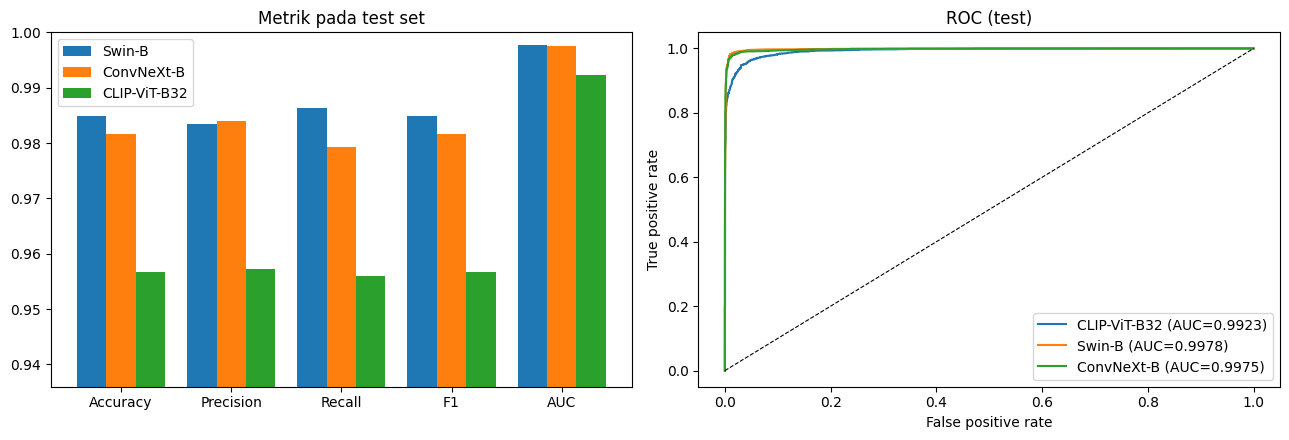

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
metrics = ["Accuracy", "Precision", "Recall", "F1", "AUC"]
x = np.arange(len(metrics)); w = 0.8 / len(comparison)
for i, row in comparison.iterrows():
    axes[0].bar(x + i * w, [row[m] for m in metrics], w, label=row["Model"])
axes[0].set_xticks(x + w * (len(comparison) - 1) / 2); axes[0].set_xticklabels(metrics)
lo = min(comparison[metrics].min()) - 0.02
axes[0].set_ylim(max(0, lo), 1.0); axes[0].set_title("Metrik pada test set"); axes[0].legend()

for name in all_results:
    d = pd.read_csv(os.path.join(OUT_DIR, name, "test_predictions.csv"))
    fpr, tpr, _ = roc_curve(d["label"], d["prob_fake"])
    axes[1].plot(fpr, tpr, label=f"{name} (AUC={all_results[name]['test']['AUC']:.4f})")
axes[1].plot([0, 1], [0, 1], "k--", lw=0.8); axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate"); axes[1].set_title("ROC (test)"); axes[1].legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "comparison_plot.png"), dpi=150); plt.show()

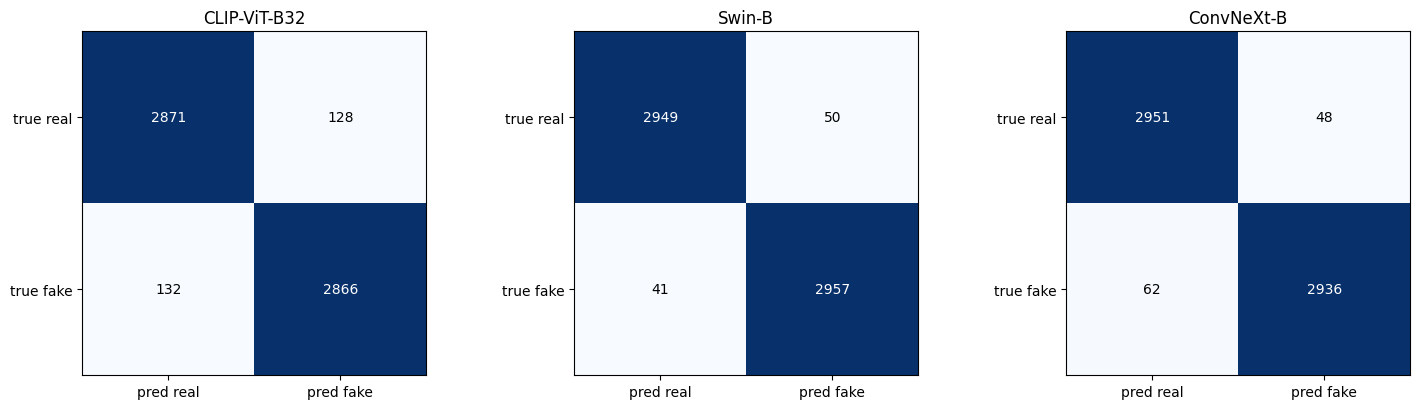

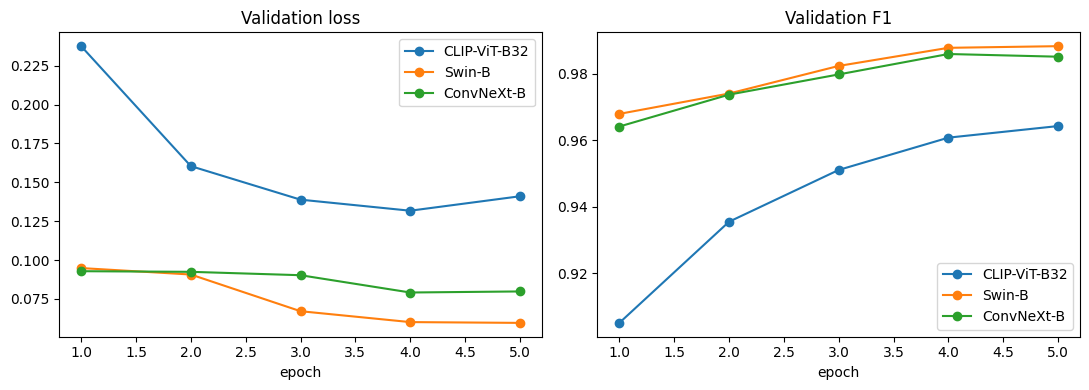

In [ ]:
fig, axes = plt.subplots(1, len(all_results), figsize=(5 * len(all_results), 4.2))
axes = np.atleast_1d(axes)
for ax, (name, r) in zip(axes, all_results.items()):
    t = r["test"]; cm = np.array([[t["TN"], t["FP"]], [t["FN"], t["TP"]]])
    ax.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, str(v), ha="center", va="center", color="white" if v > cm.max() / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["pred real", "pred fake"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["true real", "true fake"]); ax.set_title(name)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "confusion_matrices.png"), dpi=150); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name in all_results:
    h = pd.read_csv(os.path.join(OUT_DIR, name, "history.csv"))
    axes[0].plot(h["epoch"], h["val_loss"], marker="o", label=name)
    axes[1].plot(h["epoch"], h["val_f1"], marker="o", label=name)
axes[0].set_title("Validation loss"); axes[1].set_title("Validation F1")
for a in axes: a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "training_curves.png"), dpi=150); plt.show()

## 10. Uji signifikansi antar model

Selisih akurasi kecil di 12.000 citra belum tentu bermakna. Dua analisis di bawah memakai prediksi test yang sama:
- **Bootstrap 95% CI** untuk akurasi dan F1 tiap model.
- **Uji McNemar (exact)** berpasangan: apakah dua model memiliki tingkat kesalahan yang berbeda pada citra yang sama.

In [ ]:
from scipy.stats import binomtest
from itertools import combinations

preds = {n: pd.read_csv(os.path.join(OUT_DIR, n, "test_predictions.csv")) for n in all_results}
ref = next(iter(preds.values()))
for n, d in preds.items():
    assert (d["filepath"].values == ref["filepath"].values).all(), "urutan test tidak sama antar model"
y_true = ref["label"].values

rng = np.random.default_rng(SEED); B = 1000
idx = rng.integers(0, len(y_true), size=(B, len(y_true)))
ci_rows = []
for n, d in preds.items():
    pr = d["pred"].values
    accs = np.array([accuracy_score(y_true[i], pr[i]) for i in idx])
    f1s  = np.array([f1_score(y_true[i], pr[i]) for i in idx])
    ci_rows.append({"Model": n,
                    "Accuracy": accuracy_score(y_true, pr), "Acc 95% CI": f"[{np.percentile(accs, 2.5):.4f}, {np.percentile(accs, 97.5):.4f}]",
                    "F1": f1_score(y_true, pr), "F1 95% CI": f"[{np.percentile(f1s, 2.5):.4f}, {np.percentile(f1s, 97.5):.4f}]"})
ci_df = pd.DataFrame(ci_rows); ci_df.to_csv(os.path.join(OUT_DIR, "bootstrap_ci.csv"), index=False)
display(ci_df)

mc_rows = []
for a, b in combinations(preds, 2):
    ca = preds[a]["pred"].values == y_true; cb = preds[b]["pred"].values == y_true
    n_a_only = int((ca & ~cb).sum()); n_b_only = int((~ca & cb).sum()); n = n_a_only + n_b_only
    p = binomtest(min(n_a_only, n_b_only), n, 0.5).pvalue if n > 0 else 1.0
    mc_rows.append({"Model A": a, "Model B": b, "A benar & B salah": n_a_only,
                    "A salah & B benar": n_b_only, "p-value": p,
                    "Signifikan (p<0.05)": "ya" if p < 0.05 else "tidak"})
mc_df = pd.DataFrame(mc_rows); mc_df.to_csv(os.path.join(OUT_DIR, "mcnemar.csv"), index=False)
display(mc_df)

,Model,Accuracy,Acc 95% CI,F1,F1 95% CI
0,CLIP-ViT-B32,0.956645,"[0.9516, 0.9616]",0.956609,"[0.9515, 0.9615]"
1,Swin-B,0.984826,"[0.9820, 0.9882]",0.984846,"[0.9819, 0.9882]"
2,ConvNeXt-B,0.981657,"[0.9785, 0.9850]",0.981612,"[0.9784, 0.9850]"


,Model A,Model B,A benar & B salah,A salah & B benar,p-value,Signifikan (p<0.05)
0,CLIP-ViT-B32,Swin-B,37,206,1.286796e-29,ya
1,CLIP-ViT-B32,ConvNeXt-B,47,197,5.029369e-23,ya
2,Swin-B,ConvNeXt-B,49,30,4.216544e-02,ya


## 11. Analisis kesalahan (opsional)

Menampilkan citra yang salah diprediksi oleh **semua** model, berguna untuk bagian pembahasan.

Citra yang salah oleh semua model: 41 dari 5997


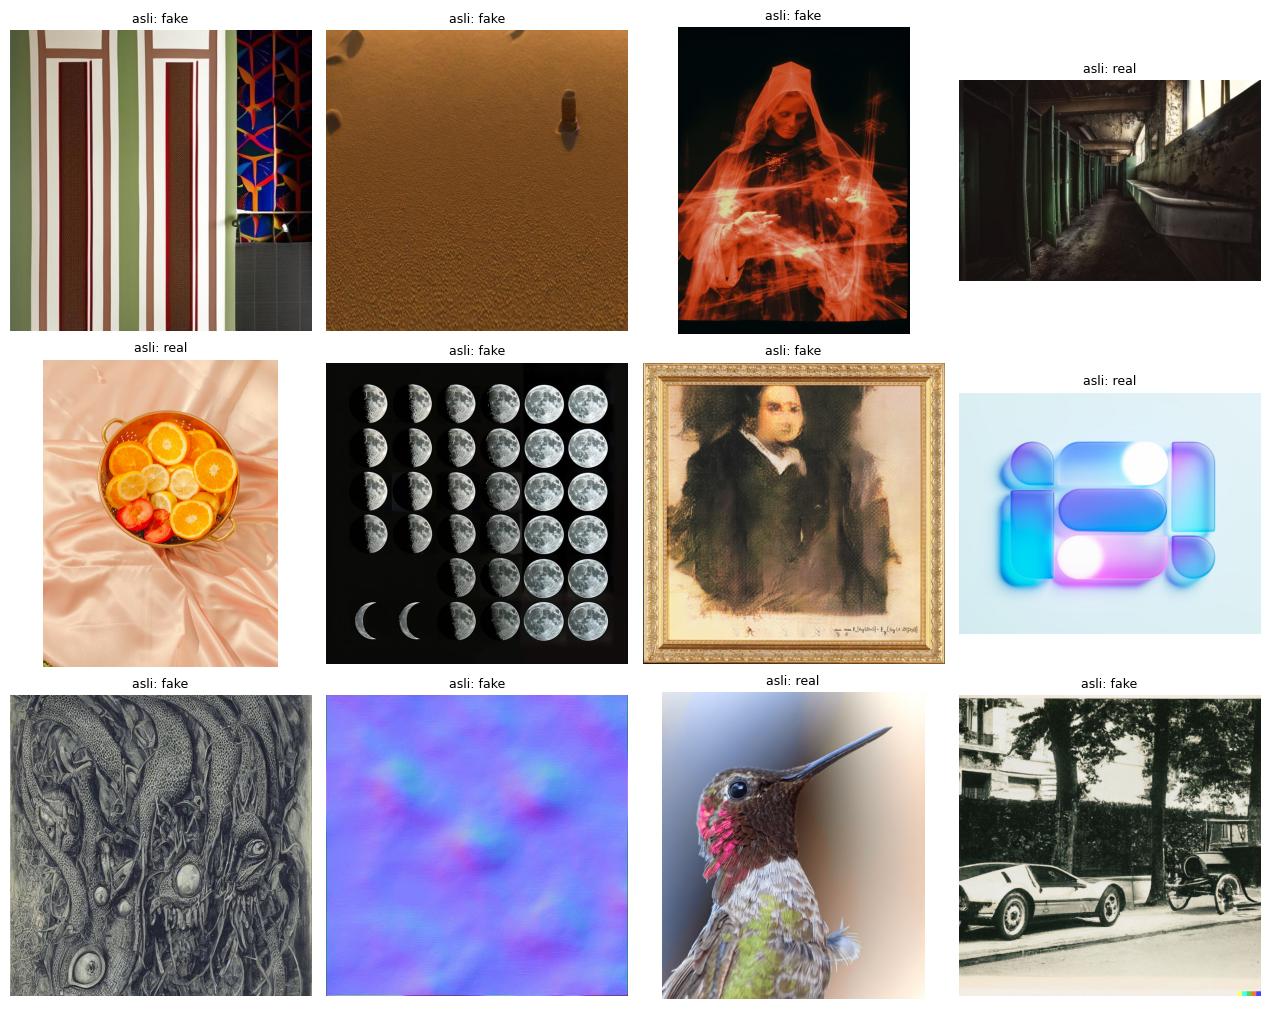

In [ ]:
wrong_all = np.ones(len(y_true), dtype=bool)
for d in preds.values(): wrong_all &= (d["pred"].values != y_true)
print("Citra yang salah oleh semua model:", wrong_all.sum(), "dari", len(y_true))

hard = ref[wrong_all].head(12)
if len(hard):
    cols = 4; rows_ = math.ceil(len(hard) / cols)
    fig, axes = plt.subplots(rows_, cols, figsize=(3.2 * cols, 3.4 * rows_)); axes = np.atleast_1d(axes).ravel()
    for ax, (_, r) in zip(axes, hard.iterrows()):
        ax.imshow(Image.open(r["filepath"]).convert("RGB")); ax.axis("off")
        ax.set_title("asli: " + CLASS_NAMES[int(r["label"])], fontsize=9)
    for ax in axes[len(hard):]: ax.axis("off")
    plt.tight_layout(); plt.show()